In [2]:
!python --version

Python 3.9.21


In [3]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2021 NVIDIA Corporation
Built on Fri_Dec_17_18:28:54_Pacific_Standard_Time_2021
Cuda compilation tools, release 11.6, V11.6.55
Build cuda_11.6.r11.6/compiler.30794723_0


In [4]:
pip install "numpy<2" --upgrade

Note: you may need to restart the kernel to use updated packages.


In [5]:
!pip install ipywidgets
!jupyter nbextension enable --py widgetsnbextension

Enabling notebook extension jupyter-js-widgets/extension...
      - Validating: ok


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import  dgl.nn as dglnn
from dgl import AddSelfLoop
from dgl.data import CoraGraphDataset
from dgl.nn.pytorch import GATConv
from dgl.nn.pytorch import GraphConv
from dgl.nn import SAGEConv
import matplotlib.pyplot as plt

In [2]:
import torchvision
import PIL
import dgl
print(torch.__version__)
print(dgl.__version__)
print(torchvision.__version__)
print(PIL.__version__)


1.13.0+cu116
1.1.2+cu116
0.14.0+cu116
11.1.0


In [3]:
transform = (
    AddSelfLoop()
)
data = CoraGraphDataset(transform=transform)
g = data[0]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
g = g.int().to(device)
features = g.ndata["feat"]
labels = g.ndata["label"]
masks = g.ndata["train_mask"], g.ndata["val_mask"], g.ndata["test_mask"]
in_size = features.shape[1]
out_size = data.num_classes
print('*' * 100)
print(g)
print('特征维度', features.shape)
print('输出维度', len(torch.unique(labels)))
print('边的条数', len(g.edges()[0]))
print('边', g.edges())

  NumNodes: 2708
  NumEdges: 10556
  NumFeats: 1433
  NumClasses: 7
  NumTrainingSamples: 140
  NumValidationSamples: 500
  NumTestSamples: 1000
Done loading data from cached files.
****************************************************************************************************
Graph(num_nodes=2708, num_edges=13264,
      ndata_schemes={'train_mask': Scheme(shape=(), dtype=torch.bool), 'label': Scheme(shape=(), dtype=torch.int64), 'val_mask': Scheme(shape=(), dtype=torch.bool), 'test_mask': Scheme(shape=(), dtype=torch.bool), 'feat': Scheme(shape=(1433,), dtype=torch.float32)}
      edata_schemes={})
特征维度 torch.Size([2708, 1433])
输出维度 7
边的条数 13264
边 (tensor([   0,    0,    0,  ..., 2705, 2706, 2707], device='cuda:0',
       dtype=torch.int32), tensor([ 633, 1862, 2582,  ..., 2705, 2706, 2707], device='cuda:0',
       dtype=torch.int32))


In [4]:
class GAT(nn.Module):
    def __init__(self, in_feats, hidden_feats,hidden2_feats, out_feats, num_heads):
        super(GAT, self).__init__()
        self.num_heads = num_heads
        self.conv1 = GATConv(in_feats, hidden_feats, num_heads)
        self.conv2 = GATConv(hidden_feats * num_heads, hidden2_feats, num_heads)
        self.conv3 = GATConv(hidden2_feats * num_heads, out_feats, num_heads)
        self.dropout = nn.Dropout(0.5)

    def forward(self, g, x):
        h = self.conv1(g, x).flatten(1)
        h = F.elu(h)
        h = self.dropout(h)
        h = self.conv2(g, h).flatten(1)
        h = F.elu(h)
        h = self.dropout(h)
        h = self.conv3(g, h).mean(1)
        return h

In [12]:
def evaluate(g, features, labels, mask, model):

    model.eval()
    with torch.no_grad():
        logits = model(g, features)

        logits = logits[mask]
        labels = labels[mask]
        # probabilities = F.softmax(logits, dim=1)
        # print(probabilities)
        _, indices = torch.max(logits, dim=1)
        correct = torch.sum(indices == labels)
        return correct.item() * 1.0 / len(labels)

train1=[]
loss1 = []
def train(g, features, labels, masks, model, epoches):
    # define train/val samples, loss function and optimizer
    train_mask = masks[0]
    val_mask = masks[1]
    loss_fcn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2, weight_decay=5e-4)

    # training loop
    for epoch in range(epoches):
        model.train()
        logits = model(g, features)
        loss = loss_fcn(logits[train_mask], labels[train_mask])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        acc = evaluate(g, features, labels, val_mask, model)

        train1.append(acc)
        loss1.append(loss.item())
        if epoch%10==0:
            print(
                "Epoch {:05d} | Loss {:.4f} | Accuracy {:.4f} ".format(
                    epoch, loss.item(), acc
                )
            )

Training...
Epoch 00000 | Loss 1.9457 | Accuracy 0.0580 
Epoch 00010 | Loss 1.8481 | Accuracy 0.7460 
Epoch 00020 | Loss 1.4618 | Accuracy 0.7460 
Epoch 00030 | Loss 0.8556 | Accuracy 0.7560 
Epoch 00040 | Loss 0.4372 | Accuracy 0.7600 
Epoch 00050 | Loss 0.2599 | Accuracy 0.7720 
Epoch 00060 | Loss 0.1684 | Accuracy 0.7520 
Epoch 00070 | Loss 0.1615 | Accuracy 0.7460 
Epoch 00080 | Loss 0.1371 | Accuracy 0.7540 
Epoch 00090 | Loss 0.1089 | Accuracy 0.7520 
Epoch 00100 | Loss 0.0934 | Accuracy 0.7500 
Epoch 00110 | Loss 0.1019 | Accuracy 0.7560 
Epoch 00120 | Loss 0.0750 | Accuracy 0.7600 
Epoch 00130 | Loss 0.0792 | Accuracy 0.7720 
Epoch 00140 | Loss 0.0878 | Accuracy 0.7500 
Epoch 00150 | Loss 0.0792 | Accuracy 0.7460 
Epoch 00160 | Loss 0.0683 | Accuracy 0.7340 
Epoch 00170 | Loss 0.0628 | Accuracy 0.7480 
Epoch 00180 | Loss 0.0660 | Accuracy 0.7600 
Epoch 00190 | Loss 0.0800 | Accuracy 0.7460 
Epoch 00200 | Loss 0.0789 | Accuracy 0.7440 
Epoch 00210 | Loss 0.0911 | Accuracy 0.7360

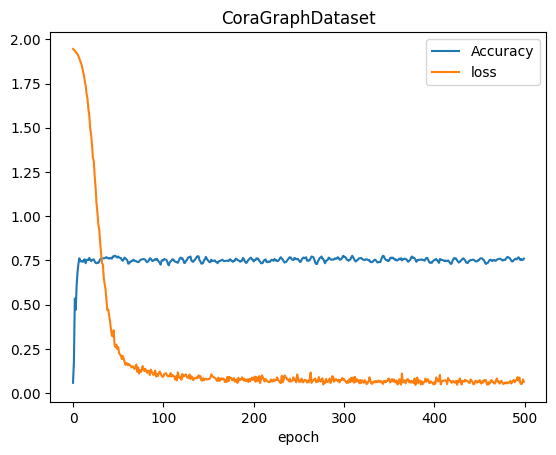

Testing...
Test accuracy 0.7810


In [6]:
model = GAT(in_size, 4,2, out_size, num_heads=8).to(device)
# model training
print("Training...")
epoches = 500
train(g, features, labels, masks, model, epoches)


plt.plot(train1,label='Accuracy')
plt.plot(loss1,label='loss')
plt.xlabel("epoch")
plt.title("CoraGraphDataset")
plt.legend()
plt.show()
# test the model
print("Testing...")
acc = evaluate(g, features, labels, masks[2], model)
print("Test accuracy {:.4f}".format(acc))

In [7]:
class GCN(nn.Module):
    def __init__(self, in_feats, hidden_feats, hidden2_feats, out_feats):
        super(GCN, self).__init__()
        self.conv1 = GraphConv(in_feats, hidden_feats)
        self.conv2 = GraphConv(hidden_feats, hidden2_feats)
        self.conv3 = GraphConv(hidden2_feats, out_feats)
        self.dropout = nn.Dropout(0.5)
    
    def forward(self, g, x):
        h = self.conv1(g, x)
        h = F.elu(h)
        h = self.dropout(h)
        
        h = self.conv2(g, h)
        h = F.elu(h)
        h = self.dropout(h)
        
        h = self.conv3(g, h)
        return h

Training...
Epoch 00000 | Loss 1.9453 | Accuracy 0.2140 
Epoch 00010 | Loss 1.8002 | Accuracy 0.5940 
Epoch 00020 | Loss 1.5239 | Accuracy 0.6400 
Epoch 00030 | Loss 1.2015 | Accuracy 0.7720 
Epoch 00040 | Loss 0.8686 | Accuracy 0.7760 
Epoch 00050 | Loss 0.6167 | Accuracy 0.7820 
Epoch 00060 | Loss 0.4478 | Accuracy 0.7700 
Epoch 00070 | Loss 0.3070 | Accuracy 0.7760 
Epoch 00080 | Loss 0.2637 | Accuracy 0.7700 
Epoch 00090 | Loss 0.2571 | Accuracy 0.7780 
Epoch 00100 | Loss 0.2194 | Accuracy 0.7800 
Epoch 00110 | Loss 0.2034 | Accuracy 0.7740 
Epoch 00120 | Loss 0.1594 | Accuracy 0.7780 
Epoch 00130 | Loss 0.1544 | Accuracy 0.7680 
Epoch 00140 | Loss 0.1588 | Accuracy 0.7700 
Epoch 00150 | Loss 0.1677 | Accuracy 0.7800 
Epoch 00160 | Loss 0.1530 | Accuracy 0.7880 
Epoch 00170 | Loss 0.1415 | Accuracy 0.7800 
Epoch 00180 | Loss 0.1439 | Accuracy 0.7740 
Epoch 00190 | Loss 0.1026 | Accuracy 0.7740 
Epoch 00200 | Loss 0.0985 | Accuracy 0.7680 
Epoch 00210 | Loss 0.1201 | Accuracy 0.7840

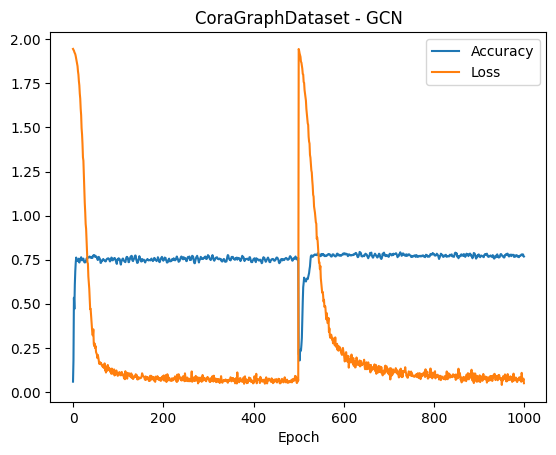

Testing...
Test accuracy 0.7810


In [8]:
# 初始化GCN模型
model = GCN(in_size, 16, 8, out_size).to(device)  # 调整了隐藏层维度

# 模型训练
print("Training...")
epochs = 500
train(g, features, labels, masks, model, epochs)

# 可视化训练过程
plt.plot(train1, label='Accuracy')
plt.plot(loss1, label='Loss')
plt.xlabel("Epoch")
plt.title("CoraGraphDataset - GCN")
plt.legend()
plt.show()

# 测试模型
print("Testing...")
acc = evaluate(g, features, labels, masks[2], model)
print("Test accuracy {:.4f}".format(acc))

In [4]:
class GraphSAGE(nn.Module):
    def __init__(self, in_feats, hidden_feats, hidden2_feats, out_feats, aggregator_type='mean'):
        super(GraphSAGE, self).__init__()
        # 第一层GraphSAGE
        self.conv1 = SAGEConv(in_feats, hidden_feats, aggregator_type)
        # 第二层GraphSAGE
        self.conv2 = SAGEConv(hidden_feats, hidden2_feats, aggregator_type)
        # 输出层
        self.conv3 = SAGEConv(hidden2_feats, out_feats, aggregator_type)
        self.dropout = nn.Dropout(0.5)
    
    def forward(self, g, x):
        h = self.conv1(g, x)
        h = F.elu(h)
        h = self.dropout(h)
        
        h = self.conv2(g, h)
        h = F.elu(h)
        h = self.dropout(h)
        
        h = self.conv3(g, h)
        return h

Training GraphSAGE...
Epoch 00000 | Loss 2.1725 | Accuracy 0.0660 
Epoch 00010 | Loss 1.2560 | Accuracy 0.6480 
Epoch 00020 | Loss 0.8224 | Accuracy 0.6760 
Epoch 00030 | Loss 0.4829 | Accuracy 0.6960 
Epoch 00040 | Loss 0.2904 | Accuracy 0.7120 
Epoch 00050 | Loss 0.2170 | Accuracy 0.7140 
Epoch 00060 | Loss 0.1370 | Accuracy 0.7240 
Epoch 00070 | Loss 0.1352 | Accuracy 0.7380 
Epoch 00080 | Loss 0.1398 | Accuracy 0.7480 
Epoch 00090 | Loss 0.1219 | Accuracy 0.7340 
Epoch 00100 | Loss 0.1510 | Accuracy 0.7460 
Epoch 00110 | Loss 0.0968 | Accuracy 0.7380 
Epoch 00120 | Loss 0.1271 | Accuracy 0.7460 
Epoch 00130 | Loss 0.0783 | Accuracy 0.7520 
Epoch 00140 | Loss 0.1136 | Accuracy 0.7560 
Epoch 00150 | Loss 0.0841 | Accuracy 0.7480 
Epoch 00160 | Loss 0.0751 | Accuracy 0.7480 
Epoch 00170 | Loss 0.0821 | Accuracy 0.7440 
Epoch 00180 | Loss 0.0689 | Accuracy 0.7400 
Epoch 00190 | Loss 0.0560 | Accuracy 0.7380 
Epoch 00200 | Loss 0.0412 | Accuracy 0.7400 
Epoch 00210 | Loss 0.0635 | Accur

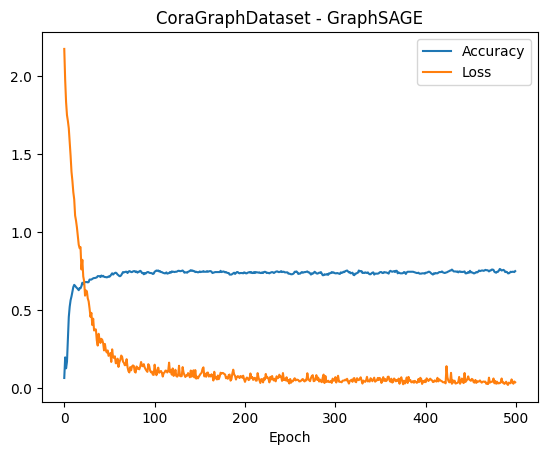

Testing...
Test accuracy 0.7900


In [7]:
# 初始化GraphSAGE模型
model = GraphSAGE(in_size, 16, 8, out_size, aggregator_type='mean').to(device)

# 模型训练
print("Training GraphSAGE...")
epochs = 500
train(g, features, labels, masks, model, epochs)

# 可视化训练过程
plt.plot(train1, label='Accuracy')
plt.plot(loss1, label='Loss')
plt.xlabel("Epoch")
plt.title("CoraGraphDataset - GraphSAGE")
plt.legend()
plt.show()

# 测试模型
print("Testing...")
acc = evaluate(g, features, labels, masks[2], model)
print("Test accuracy {:.4f}".format(acc))

Training VGAE...
Epoch 00000 | Loss 2.0942 | Accuracy 0.0580
Epoch 00010 | Loss 1.9873 | Accuracy 0.2580
Epoch 00020 | Loss 1.8990 | Accuracy 0.6020
Epoch 00030 | Loss 1.8500 | Accuracy 0.6980
Epoch 00040 | Loss 1.7407 | Accuracy 0.6760
Epoch 00050 | Loss 1.6251 | Accuracy 0.6560
Epoch 00060 | Loss 1.5261 | Accuracy 0.6860
Epoch 00070 | Loss 1.4548 | Accuracy 0.6760
Epoch 00080 | Loss 1.4130 | Accuracy 0.6520
Epoch 00090 | Loss 1.3771 | Accuracy 0.6580
Epoch 00100 | Loss 1.3512 | Accuracy 0.6280
Epoch 00110 | Loss 1.2433 | Accuracy 0.6260
Epoch 00120 | Loss 1.1573 | Accuracy 0.6440
Epoch 00130 | Loss 1.1059 | Accuracy 0.6380
Epoch 00140 | Loss 1.0438 | Accuracy 0.6400
Epoch 00150 | Loss 1.0126 | Accuracy 0.6340
Epoch 00160 | Loss 1.0199 | Accuracy 0.6240
Epoch 00170 | Loss 1.0482 | Accuracy 0.6240
Epoch 00180 | Loss 0.8941 | Accuracy 0.6680
Epoch 00190 | Loss 1.0199 | Accuracy 0.6460
Epoch 00200 | Loss 0.9167 | Accuracy 0.6660
Epoch 00210 | Loss 0.9143 | Accuracy 0.6600
Epoch 00220 | L

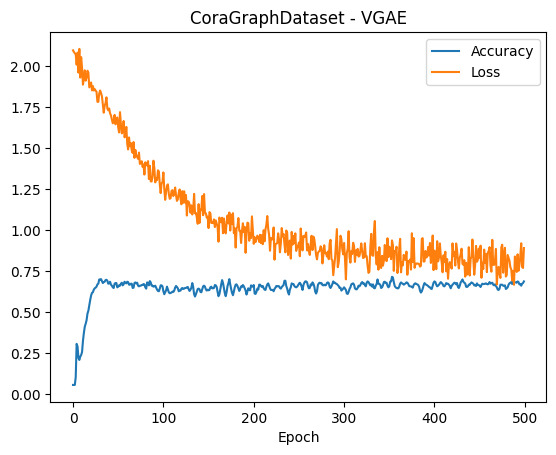

Testing...
Test accuracy 0.7160


In [17]:
class VGAE(nn.Module):
    def __init__(self, in_feats, hidden_feats, hidden2_feats, out_feats):
        super(VGAE, self).__init__()
        # 编码器部分
        self.conv1 = GraphConv(in_feats, hidden_feats)
        self.conv_mu = GraphConv(hidden_feats, hidden2_feats)  # 均值
        self.conv_logvar = GraphConv(hidden_feats, hidden2_feats)  # 对数方差
        self.conv_out = GraphConv(hidden2_feats, out_feats)  # 输出层
        self.dropout = nn.Dropout(0.5)
    
    def encode(self, g, x):
        h = F.relu(self.conv1(g, x))
        h = self.dropout(h)
        mu = self.conv_mu(g, h)
        logvar = self.conv_logvar(g, h)
        return mu, logvar
    
    def reparameterize(self, mu, logvar):
        if self.training:
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        else:
            return mu
    
    def forward(self, g, x):
        mu, logvar = self.encode(g, x)
        z = self.reparameterize(mu, logvar)
        out = self.conv_out(g, z)
        return out, mu, logvar  # 返回分类输出和分布参数

# 修改后的损失函数
def loss_function(logits, labels, mask, mu, logvar):
    # 分类损失
    ce_loss = F.cross_entropy(logits[mask], labels[mask])
    # KL散度
    kl_loss = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
    return ce_loss + kl_loss

# 修改后的训练函数
train_acc = []
loss_list = []

def evaluate(g, features, labels, mask, model):
    model.eval()
    with torch.no_grad():
        logits, _, _ = model(g, features)  # 只取分类输出
        logits = logits[mask]
        labels = labels[mask]
        _, indices = torch.max(logits, dim=1)
        correct = torch.sum(indices == labels)
        return correct.item() * 1.0 / len(labels)

def train(g, features, labels, masks, model, epochs):
    train_mask, val_mask, _ = masks
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2, weight_decay=5e-4)
    
    for epoch in range(epochs):
        model.train()
        logits, mu, logvar = model(g, features)  # 获取所有输出
        loss = loss_function(logits, labels, train_mask, mu, logvar)  # 使用新损失函数
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        acc = evaluate(g, features, labels, val_mask, model)
        train_acc.append(acc)
        loss_list.append(loss.item())
        
        if epoch % 10 == 0:
            print(f"Epoch {epoch:05d} | Loss {loss.item():.4f} | Accuracy {acc:.4f}")

# 初始化模型
model = VGAE(in_size, 16, 8, out_size).to(device)

# 训练模型
print("Training VGAE...")
epochs = 500
train(g, features, labels, masks, model, epochs)

# 可视化
plt.plot(train_acc, label='Accuracy')
plt.plot(loss_list, label='Loss')
plt.xlabel("Epoch")
plt.title("CoraGraphDataset - VGAE")
plt.legend()
plt.show()

# 测试
print("Testing...")
acc = evaluate(g, features, labels, masks[2], model)
print(f"Test accuracy {acc:.4f}")